# Лабораторная работа 3
> - **Предмет:** МОСИИ
> - **Студент:** Руденко Андрей Артемович
> - **Группа:** М9125-01.04.02МКТ

**Цель работы:** Обучение многослойного персептрона на датасете животных из приюта и сравнение подходов к масштабированию данных.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset, Sampler
from torch.utils.data.dataloader import default_collate
from torch.utils.tensorboard import SummaryWriter

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

## Загрузка данных

In [2]:
X = pd.read_csv('X_cat.csv', sep='\t', index_col=0)
target = pd.read_csv('y_cat.csv', sep='\t', index_col=0, names=['status'])

print(X.shape)
target['status'].value_counts(normalize=True)

(26729, 37)


status
Adoption           0.402896
Transfer           0.352501
Return_to_owner    0.179056
Euthanasia         0.058177
Died               0.007370
Name: proportion, dtype: float64

Около 27 тысяч животных и 37 признаков. Классов 5, класс `Died` меньше 1%, поэтому объединяем его с `Euthanasia`, остаётся 4 класса. Классы несбалансированы: самый частый `Adoption`, около 40%.

## Предобработка признаков

День недели, час и месяц — циклические признаки: 23 часа и 0 часов рядом, а числами они далеко. Поэтому переводим их в синус и косинус, тогда соседние значения на круге получаются близкими. День недели закодирован семью колонками `Weekday_0…6`, сначала собираем его в одно число.

In [3]:
target.loc[target['status'] == 'Died', 'status'] = 'Euthanasia'
le = LabelEncoder()
y = le.fit_transform(target['status'])

weekday_columns = [f'Weekday_{i}' for i in range(7)]
weekdays = np.argmax(X[weekday_columns].values, axis=1)
X = X.drop(columns=weekday_columns)

X['Weekday_cos'] = np.cos(2 * np.pi / 7 * weekdays)
X['Weekday_sin'] = np.sin(2 * np.pi / 7 * weekdays)
X['Hour_cos'] = np.cos(2 * np.pi / 24 * X['Hour'])
X['Hour_sin'] = np.sin(2 * np.pi / 24 * X['Hour'])
X['Month_cos'] = np.cos(2 * np.pi / 12 * X['Month'])
X['Month_sin'] = np.sin(2 * np.pi / 12 * X['Month'])
X = X.drop(columns=['Hour', 'Month'])

print(X.shape, le.classes_)

(26729, 34) ['Adoption' 'Euthanasia' 'Return_to_owner' 'Transfer']


Делим выборку на train/valid в соотношении 80/20, с сохранением долей классов.

In [4]:
X_train, X_valid, y_train, y_valid = train_test_split(X.values.astype(np.float32), y,
                                                      test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_valid.shape)

(21383, 34) (5346, 34)


## Baseline

Чтобы было с чем сравнивать нейросеть: прогноз самым частым классом и логистическая регрессия.

In [5]:
most_frequent = np.bincount(y_train).argmax()
print(f'Самый частый класс: {accuracy_score(y_valid, np.full(len(y_valid), most_frequent)):.3f}')

scaler = StandardScaler()
logreg = LogisticRegression(max_iter=1000)
logreg.fit(scaler.fit_transform(X_train), y_train)
print(f'Логистическая регрессия: {accuracy_score(y_valid, logreg.predict(scaler.transform(X_valid))):.3f}')

Самый частый класс: 0.403
Логистическая регрессия: 0.640


## Custom Dataset, Sampler, collate_fn

In [6]:
class CustomDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


class CustomSampler(Sampler):
    # каждую эпоху выдаёт индексы объектов в новом случайном порядке
    def __init__(self, data):
        self.data_indices = np.arange(len(data))

    def __len__(self):
        return len(self.data_indices)

    def __iter__(self):
        return iter(np.random.permutation(self.data_indices).tolist())


def collate(batch):
    # склеивает список объектов в тензоры батча
    features, labels = default_collate(batch)
    return features.float(), labels.long()

## Модель

MLP с двумя скрытыми слоями по 64 нейрона, после каждого BatchNorm, ReLU и Dropout. BatchNorm на входе включается флагом `input_bn`, это нужно для сравнения подходов. Сеть небольшая, 30 эпох хватает: accuracy на valid перестаёт расти примерно к середине обучения.

In [7]:
class MLPNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, input_bn, dropout=0.2):
        super().__init__()
        self.input_bn = nn.BatchNorm1d(input_size) if input_bn else nn.Identity()
        self.layers = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size),
            nn.BatchNorm1d(hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, output_size),
        )

    def forward(self, x):
        return self.layers(self.input_bn(x))

## Обучение

Одна функция на все эксперименты: масштабирует данные или нет, собирает DataLoader и модель, обучает и пишет loss и accuracy на train и valid в TensorBoard, каждый эксперимент в свою папку `logs/<название>`.

In [8]:
import shutil
shutil.rmtree('logs', ignore_errors=True)  # убираем логи прошлых запусков

INPUT_SIZE = X_train.shape[1]
HIDDEN_SIZE = 64
OUTPUT_SIZE = 4
LEARNING_RATE = 1e-3
EPOCHS = 30
BATCH_SIZE = 256


def run_experiment(name, scale, input_bn):
    torch.manual_seed(42)
    np.random.seed(42)

    X_tr, X_va = X_train, X_valid
    if scale:
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_tr)
        X_va = scaler.transform(X_va)

    train_ds = CustomDataset(X_tr, y_train)
    valid_ds = CustomDataset(X_va, y_valid)
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=CustomSampler(train_ds), collate_fn=collate)
    valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, collate_fn=collate)

    model = MLPNet(INPUT_SIZE, HIDDEN_SIZE, OUTPUT_SIZE, input_bn)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    writer = SummaryWriter(f'logs/{name}')

    history = []
    for epoch in range(EPOCHS):
        model.train()
        train_loss, train_correct = 0, 0
        for features, labels in train_loader:
            optimizer.zero_grad()
            output = model(features)
            loss = criterion(output, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * len(labels)
            train_correct += (output.argmax(dim=1) == labels).sum().item()

        model.eval()
        valid_loss, valid_correct = 0, 0
        valid_preds = []
        with torch.no_grad():
            for features, labels in valid_loader:
                output = model(features)
                valid_loss += criterion(output, labels).item() * len(labels)
                valid_correct += (output.argmax(dim=1) == labels).sum().item()
                valid_preds.append(output.argmax(dim=1).numpy())

        train_acc = train_correct / len(train_ds)
        valid_acc = valid_correct / len(valid_ds)
        writer.add_scalar('Loss/train', train_loss / len(train_ds), epoch)
        writer.add_scalar('Loss/valid', valid_loss / len(valid_ds), epoch)
        writer.add_scalar('Accuracy/train', train_acc, epoch)
        writer.add_scalar('Accuracy/valid', valid_acc, epoch)
        history.append(valid_acc)
        last_preds = valid_preds

    writer.close()
    print(f'{name}: accuracy на train {train_acc:.3f}, на valid {valid_acc:.3f}')
    return history, np.concatenate(last_preds)

## Эксперимент 1: StandardScaler, без BatchNorm на входе

In [9]:
history_1, preds_1 = run_experiment('scaler', scale=True, input_bn=False)

scaler: accuracy на train 0.677, на valid 0.676


## Вывод работы эксперимента 1

Accuracy на valid 0.676, порог 65% пройден. StandardScaler приводит все признаки к одному масштабу, и сеть учится ровно.

## Эксперимент 2: без масштабирования, BatchNorm на входе

In [10]:
history_2, preds_2 = run_experiment('input_bn', scale=False, input_bn=True)

input_bn: accuracy на train 0.676, на valid 0.677


## Вывод работы эксперимента 2

0.677, почти как в эксперименте 1. BatchNorm на входе делает почти то же, что StandardScaler, только внутри сети: при обучении нормирует каждый признак по батчу, а при предсказании по накопленным средним.

## Эксперимент 3: StandardScaler и BatchNorm на входе

In [11]:
history_3, preds_3 = run_experiment('scaler_input_bn', scale=True, input_bn=True)

scaler_input_bn: accuracy на train 0.678, на valid 0.677


## Вывод работы эксперимента 3

0.677. Вместе они ничего не добавляют: после StandardScaler признаки уже нормированы, и BatchNorm на входе почти ничего не меняет.

## Эксперимент 4: без масштабирования и без BatchNorm на входе

In [12]:
history_4, preds_4 = run_experiment('no_scaling', scale=False, input_bn=False)

no_scaling: accuracy на train 0.639, на valid 0.623


## Вывод работы эксперимента 4

Для сравнения убрал и то, и другое. Accuracy на valid сильно скачет от эпохи к эпохе (видно на общем графике ниже) и остаётся хуже логистической регрессии. Признаки в очень разных масштабах: возраст в днях доходит до 7300, год около 2014, а большинство остальных 0 или 1, поэтому сеть учится рывками.

## Технический отчёт

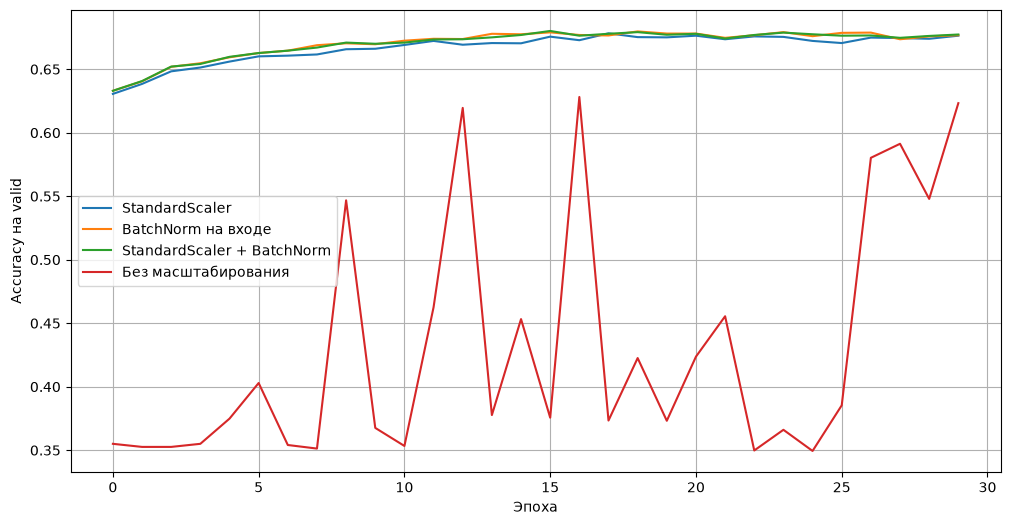

In [13]:
plt.figure(figsize=(12, 6))
plt.plot(history_1, label='StandardScaler')
plt.plot(history_2, label='BatchNorm на входе')
plt.plot(history_3, label='StandardScaler + BatchNorm')
plt.plot(history_4, label='Без масштабирования')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy на valid')
plt.legend()
plt.grid()
plt.show()

| Модель | Accuracy на valid |
|---|---|
| Самый частый класс | 0.403 |
| Логистическая регрессия (baseline) | 0.640 |
| MLP без масштабирования и без BatchNorm на входе | 0.623 |
| MLP, StandardScaler | 0.676 |
| MLP, BatchNorm на входе | 0.677 |
| MLP, StandardScaler + BatchNorm на входе | 0.677 |

Baseline — логистическая регрессия на тех же признаках, 0.640. MLP перебивает её на 3.6–3.7 процентных пункта и проходит порог 65% во всех трёх вариантах с масштабированием, скорее всего, за счёт нелинейных скрытых слоёв. Но только если признаки приведены к одному масштабу: без этого сеть хуже логистической регрессии.

Как именно масштабировать, почти не важно: StandardScaler, BatchNorm на входе или оба сразу дают одинаковый результат, разница в третьем знаке. Удобство BatchNorm в том, что нормировка становится частью модели и не нужно отдельно хранить scaler.

Классы несбалансированы, поэтому для варианта StandardScaler + BatchNorm смотрю качество по каждому классу:

In [14]:
from sklearn.metrics import classification_report
print(classification_report(y_valid, preds_3, target_names=le.classes_, digits=3))

                 precision    recall  f1-score   support

       Adoption      0.705     0.821     0.759      2154
     Euthanasia      0.671     0.163     0.262       350
Return_to_owner      0.483     0.520     0.501       957
       Transfer      0.753     0.689     0.720      1885

       accuracy                          0.677      5346
      macro avg      0.653     0.548     0.560      5346
   weighted avg      0.680     0.677     0.666      5346



Хуже всего модель находит `Euthanasia`: recall 0.163, то есть узнаёт только каждый шестой такой случай. Это самый редкий класс, около 7% выборки, и модель чаще относит такие объекты к другим классам. Лучше всего распознаётся самый частый класс `Adoption` (recall 0.821). Так что общая accuracy 0.677 держится в основном на крупных классах. Чтобы модель чаще находила редкий класс, можно задать веса классов в `CrossEntropyLoss`, но тогда, скорее всего, немного упадёт accuracy на частых классах.